# IS630: Green Light for an Indie Studio
## Notebook 01: Exploratory Data Analysis
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All code blocks below are labeled as AI-assisted. All modelling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below.

This notebook works through one data question per section, building towards **AQ1: what is a good metric for evaluating a game's success?**

| Section | Question |
|---|---|
| 1 | What does our data look like, and how are the variables distributed? |
| 2 | Where is data missing, and what anomalies does the data contain? |
| 3 | What are the prospective target variables, and which one makes sense? |
| 4 | What bias did the merge introduce, and is the matched set representative? |
| 5 | What do the top games look like, against the rest of the population? |
| 6 | How does game age affect reception? |
| 7 | How do the variables correlate? |
| 8 | *Suggested*: how much evidence sits behind each estimate? |

Every column carries its source as a prefix. `steam_` comes from the Steam dataset and `hltb_` from HowLongToBeat. Four columns describe the join itself or combine both sources, so they carry no prefix: `title_key`, `matched_hltb`, `year_diff` and `completion_ratio`.

Where a variable is plotted on a log scale, the untransformed version is shown beside it.

**Reads:** `data/interim/00_train.parquet`
**Writes:** `data/interim/01_eda.parquet`, figures to `outputs/figures`

The held-out test set is never loaded here. Every figure and statistic below describes the training set only.

## Setup
*Code: Generated by AI Assistant*

*Written by AI Assistant*: `raw_vs_log` plots any heavy-tailed variable twice, untransformed and then on a log10 scale, so the transformation never hides what the original looked like. The raw panel is clipped at a stated percentile, otherwise a few extreme values compress everything else into the first bin.

In [1]:
# Reload src/is630 whenever it changes. Without this, a kernel left running keeps
# the first version of each module it imported, and edits to features.py or
# config.py are silently ignored until the kernel restarts.
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except NameError:
    pass  # not running under IPython

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config
from is630.features import add_derived

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 10.5
plt.rcParams["axes.labelsize"] = 9.5
pd.set_option("display.width", 200)

config.FIGURES.mkdir(parents=True, exist_ok=True)
for stale in config.FIGURES.glob("01_*.png"):
    stale.unlink()  # clear this notebook's figures so outputs match the current run

def save_fig(fig, name):
    """Write a figure to outputs/figures at 300 dpi."""
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

def ascii_names(s):
    """Strip non-ASCII title characters so tables print cleanly in any console."""
    return s.astype(str).str.encode("ascii", "replace").str.decode("ascii")

def raw_vs_log(axes_pair, series, label, colour="steelblue", clip_q=0.99, drop_zero=True):
    """Plot a variable untransformed on the left and log10 on the right.

    The raw panel is clipped at a high percentile, otherwise a handful of extreme
    values compress everything else into the first bin. The clip point is stated
    in the title. Zeros are dropped from the log panel because log10(0) is
    undefined, and the count dropped is stated."""
    ax_raw, ax_log = axes_pair
    s = series.dropna()

    cut = s.quantile(clip_q)
    shown = s[s <= cut]
    ax_raw.hist(shown, bins=50, color=colour, edgecolor="black", alpha=0.85)
    ax_raw.set_title(f"{label}\nraw, clipped at p{int(clip_q * 100)} = {cut:,.2f}")
    ax_raw.set_xlabel(label)

    pos = s[s > 0] if drop_zero else s
    n_zero = int((s <= 0).sum())
    ax_log.hist(np.log10(pos), bins=50, color=colour, edgecolor="black", alpha=0.85)
    ax_log.set_title(f"{label}\nlog10, {n_zero:,} non-positive dropped")
    ax_log.set_xlabel(f"log10({label})")

In [2]:
train = pd.read_parquet(config.INTERIM / "00_train.parquet")
print(f"rows in: {len(train):,}")

df = add_derived(train)
matched = df[df["matched_hltb"]].copy()
print(f"matched to HowLongToBeat: {len(matched):,} ({len(matched) / len(df) * 100:.1f}%)")
print(f"columns: {train.shape[1]} in, {df.shape[1]} after derived columns")

rows in: 97,026
matched to HowLongToBeat: 16,660 (17.2%)
columns: 72 in, 81 after derived columns


## 1. What does our data look like?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: columns are grouped by what they describe rather than listed in file order. The source prefix is what separates the two datasets' name, date, genre and hour columns.

In [3]:
# What the columns are, grouped by what they describe
groups = {
    "Identity": ["steam_appid", "steam_name", "steam_release_date", "steam_year", "steam_years_since_release"],
    "Reception": ["steam_positive", "steam_negative", "steam_review_count", "steam_positive_rate",
                  "steam_metacritic_score", "steam_user_score", "steam_recommendations"],
    "Engagement": ["steam_median_playtime_forever", "steam_playtime_hours", "steam_average_playtime_forever",
                   "steam_peak_ccu", "steam_estimated_owners", "steam_owners_lower", "steam_owners_upper"],
    "Controllable": ["steam_price", "steam_achievements", "steam_dlc_count", "steam_language_count",
                     "steam_required_age", "steam_genres", "steam_categories", "steam_tags"],
    "HowLongToBeat": ["hltb_main_story", "hltb_main_story_polled", "hltb_main_plus_sides", "hltb_completionist"],
    "Join": ["title_key", "matched_hltb", "year_diff", "completion_ratio"],
}
rows = []
for group, cols in groups.items():
    for col in cols:
        if col in df.columns:
            rows.append({"group": group, "column": col, "dtype": str(df[col].dtype),
                         "n_unique": df[col].nunique(), "pct_null": round(df[col].isna().mean() * 100, 1)})
schema = pd.DataFrame(rows)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns\n")
schema

97,026 rows x 81 columns



,group,column,dtype,n_unique,pct_null
0,Identity,steam_appid,int64,97026,0.0
1,Identity,steam_name,object,97026,0.0
2,Identity,steam_release_date,object,4993,0.0
3,Identity,steam_year,int32,30,0.0
4,Identity,steam_years_since_release,int32,30,0.0
5,Reception,steam_positive,int64,4773,0.0
6,Reception,steam_negative,int64,2349,0.0
7,Reception,steam_review_count,int64,5079,0.0
8,Reception,steam_positive_rate,float64,14758,33.5
9,Reception,steam_metacritic_score,int64,72,0.0


In [4]:
cols = ["steam_price", "steam_achievements", "steam_dlc_count", "steam_language_count",
        "steam_required_age", "steam_years_since_release", "steam_review_count",
        "steam_playtime_hours", "hltb_main_story"]
desc = df[cols].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T
desc["skew"] = df[cols].skew()
desc["pct_zero"] = (df[cols] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max,skew,pct_zero
steam_price,97026.0,4.82,11.94,0.00,0.59,2.40,5.59,14.99,29.99,999.98,17.73,20.72
steam_achievements,97026.0,18.48,146.01,0.00,0.00,3.00,19.00,55.00,100.00,9821.00,32.13,47.81
steam_dlc_count,97026.0,0.53,15.12,0.00,0.00,0.00,0.00,2.00,7.00,3703.00,184.49,85.48
steam_language_count,97026.0,5.32,13.60,0.00,1.00,1.00,5.00,16.00,103.00,103.00,6.08,6.48
steam_required_age,97026.0,0.16,1.64,0.00,0.00,0.00,0.00,0.00,10.00,21.00,9.98,98.98
steam_years_since_release,97026.0,4.39,3.32,0.00,2.00,4.00,6.00,10.00,14.00,29.00,1.05,2.57
steam_review_count,97026.0,1195.61,34699.85,0.00,0.00,7.00,48.00,1327.00,15287.00,8815087.00,180.41,33.45
steam_playtime_hours,97026.0,2.80,187.99,0.00,0.00,0.00,0.00,6.76,26.66,57159.07,290.59,78.68
hltb_main_story,16660.0,7.50,21.87,0.01,1.33,3.51,8.18,26.33,53.02,1591.65,40.14,0.00


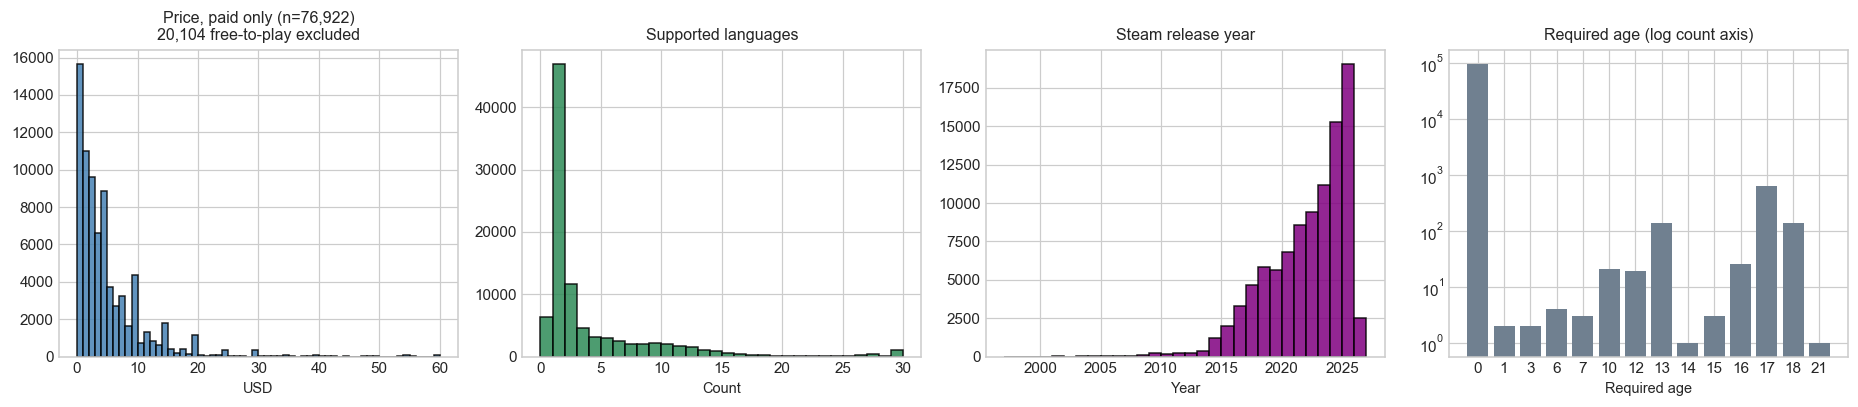

In [5]:
# Variables that need no transformation
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))

paid = df.loc[df["steam_price"] > 0, "steam_price"]
axes[0].hist(paid, bins=60, range=(0, 60), color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_title(f"Price, paid only (n={len(paid):,})\n{(df['steam_price'] == 0).sum():,} free-to-play excluded")
axes[0].set_xlabel("USD")

axes[1].hist(df["steam_language_count"], bins=range(0, 31), color="seagreen", edgecolor="black", alpha=0.85)
axes[1].set_title("Supported languages")
axes[1].set_xlabel("Count")

yrs = df["steam_year"].dropna()
axes[2].hist(yrs, bins=range(int(yrs.min()), int(yrs.max()) + 2), color="purple", edgecolor="black", alpha=0.85)
axes[2].set_title("Steam release year")
axes[2].set_xlabel("Year")

age = df["steam_required_age"].value_counts().sort_index()
axes[3].bar(age.index.astype(str), age.values, color="slategray")
axes[3].set_yscale("log")
axes[3].set_title("Required age (log count axis)")
axes[3].set_xlabel("Required age")

plt.tight_layout()
save_fig(fig, "01_q1_variables_untransformed")
plt.show()

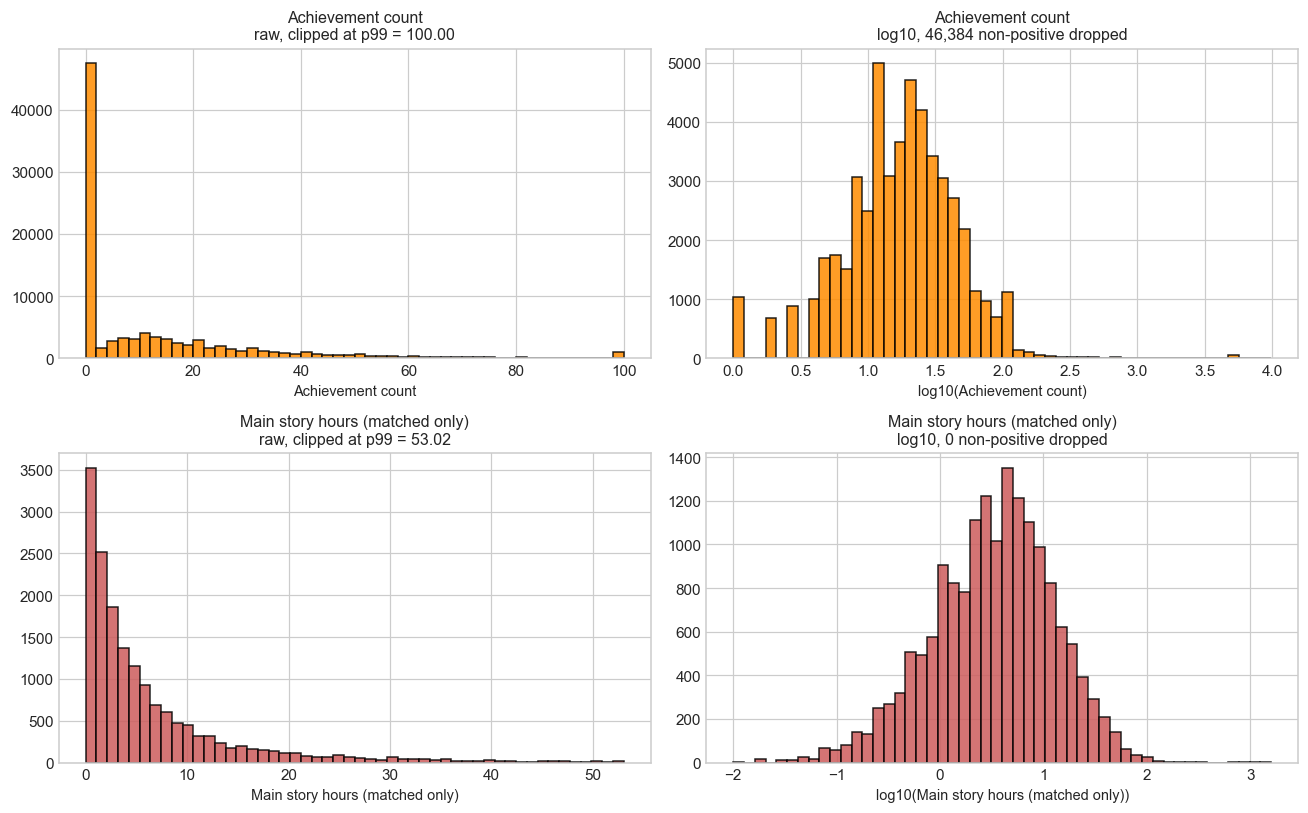

In [6]:
# Heavy-tailed variables, shown raw and then log10
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
raw_vs_log(axes[0], df["steam_achievements"], "Achievement count", "darkorange")
raw_vs_log(axes[1], matched["hltb_main_story"], "Main story hours (matched only)", "indianred")
plt.tight_layout()
save_fig(fig, "01_q1_heavy_tailed_raw_vs_log")
plt.show()

In [7]:
def top_tokens(series, n=12):
    tok = series.fillna("").str.split(",").explode().str.strip()
    tok = tok[tok.ne("")]
    out = tok.value_counts().head(n).to_frame("games")
    out["pct_of_rows"] = (out["games"] / len(series) * 100).round(1)
    return out

for name in ["steam_genres", "steam_categories"]:
    print(f"--- Top {name} ---")
    print(top_tokens(df[name]).to_string())
    print()

--- Top steam_genres ---
                       games  pct_of_rows
steam_genres                             
Indie                  64143         66.1
Casual                 39941         41.2
Action                 36976         38.1
Adventure              35673         36.8
Simulation             19274         19.9
Strategy               17698         18.2
RPG                    16168         16.7
Free To Play            9393          9.7
Early Access            8944          9.2
Sports                  3930          4.1
Racing                  3290          3.4
Massively Multiplayer   1850          1.9

--- Top steam_categories ---
                            games  pct_of_rows
steam_categories                              
Single-player               85866         88.5
Family Sharing              76541         78.9
Steam Achievements          45005         46.4
Steam Cloud                 24544         25.3
Full controller support     20561         21.2
Multi-player                

### Interpretation: What the data looks like
**Author**: [Insert Name]  
<!-- Describe the shape of the training set and the distribution of the main variables. Cover which variables are heavily skewed or zero-inflated, whether the log view changes what you conclude from the raw view, which variables will need a transformation before modelling, how concentrated the release years are, and which genres and categories dominate the catalogue. -->


## 2. Missingness and data anomalies
*Code: Generated by AI Assistant*

*Written by AI Assistant*: a zero in this data can mean three different things, so they are separated below: a sentinel for absent, an unobserved outcome, and a genuine value such as a free-to-play price. Three anomalies follow: software sold on Steam that is not a game, implausible playtimes, and duplicate or inconsistent keys.

In [8]:
# Three different kinds of absence, which pandas shows identically as 0 or NaN
sentinel = pd.DataFrame([
    {"column": "steam_metacritic_score", "kind": "0 means absent", "n": int((df["steam_metacritic_score"] == 0).sum())},
    {"column": "steam_median_playtime_forever", "kind": "0 means SteamSpy could not estimate", "n": int((df["steam_median_playtime_forever"] == 0).sum())},
    {"column": "steam_review_count", "kind": "0 means outcome never observed", "n": int((df["steam_review_count"] == 0).sum())},
    {"column": "steam_price", "kind": "0 is a real value, free-to-play", "n": int((df["steam_price"] == 0).sum())},
    {"column": "steam_achievements", "kind": "0 is a real value, no achievements", "n": int((df["steam_achievements"] == 0).sum())},
    {"column": "hltb_main_story", "kind": "NaN means unmatched or no HLTB time", "n": int(df["hltb_main_story"].isna().sum())},
])
sentinel["pct"] = (sentinel["n"] / len(df) * 100).round(1)
print(sentinel.to_string(index=False))
print("\nColumns with true nulls:")
print(df.isna().sum()[lambda s: s > 0].sort_values(ascending=False).head(15).to_string())

                       column                                kind     n  pct
       steam_metacritic_score                      0 means absent 93661 96.5
steam_median_playtime_forever 0 means SteamSpy could not estimate 76341 78.7
           steam_review_count      0 means outcome never observed 32458 33.5
                  steam_price     0 is a real value, free-to-play 20104 20.7
           steam_achievements  0 is a real value, no achievements 46384 47.8
              hltb_main_story NaN means unmatched or no HLTB time 80366 82.8

Columns with true nulls:
steam_movies                   97026
steam_score_rank               96997
hltb_versus                    96526
hltb_versus_polled             96526
hltb_co_op_polled              95940
hltb_co_op                     95940
steam_metacritic_url           93661
steam_reviews                  87420
hltb_main_plus_sides_polled    86177
hltb_main_plus_sides           86072
hltb_completionist_polled      85169
hltb_completionist          

In [9]:
# Anomaly 1: rows that are software rather than games
NON_GAME_GENRES = {
    "Utilities", "Design & Illustration", "Animation & Modeling", "Audio Production",
    "Video Production", "Photo Editing", "Software Training", "Web Publishing",
    "Game Development", "Accounting",
}
genre_sets = df["steam_genres"].fillna("").apply(lambda x: {t.strip() for t in x.split(",")})
df["steam_is_software"] = genre_sets.apply(lambda s: bool(NON_GAME_GENRES & s))

print(f"rows carrying a non-game genre: {df['steam_is_software'].sum():,} ({df['steam_is_software'].mean() * 100:.1f}%)")
print(f"  among the 100 highest playtimes: {df.nlargest(100, 'steam_playtime_hours')['steam_is_software'].sum()}")
print(f"  among matched rows: {df.loc[df['matched_hltb'], 'steam_is_software'].sum():,} of {int(df['matched_hltb'].sum()):,}")
show = df[df["steam_is_software"]].nlargest(8, "steam_playtime_hours")[
    ["steam_name", "steam_playtime_hours", "steam_review_count", "steam_genres"]].copy()
show["steam_name"] = ascii_names(show["steam_name"])
show["steam_genres"] = ascii_names(show["steam_genres"])
show.round(1)

rows carrying a non-game genre: 1,339 (1.4%)
  among the 100 highest playtimes: 16
  among matched rows: 9 of 16,660


,steam_name,steam_playtime_hours,steam_review_count,steam_genres
3509,VEGAS Pro 18 Edit Steam Edition,3084.3,2337,"Audio Production,Video Production"
9641,Ai Vpet,1767.2,375,"Casual,Simulation,Utilities"
10034,Energy Engine PC Live Wallpaper,1605.4,347,"Design & Illustration,Utilities"
19643,Reality Mixer - Mixed Reality for VR headsets,1078.8,81,Utilities
6746,Boom 3D Windows: Experience 3D surround sound ...,1044.6,730,"Audio Production,Utilities"
25307,Mosaico,961.3,44,Utilities
7034,RainWallpaper,957.3,677,"Animation & Modeling,Design & Illustration,Uti..."
15847,MediBang Paint for Desktop,709.2,132,"Animation & Modeling,Design & Illustration,Pho..."


In [10]:
# Anomaly 2: implausible playtime
print(f"playtime > 1,000 h : {(df['steam_playtime_hours'] > 1000).sum():,} games")
print(f"playtime > 8,760 h : {(df['steam_playtime_hours'] > 8760).sum():,} games (more than a year of wall-clock)")
print(f"playtime == 0      : {(df['steam_playtime_hours'] == 0).sum():,} games ({(df['steam_playtime_hours'] == 0).mean() * 100:.1f}%)")

extreme = df.nlargest(10, "steam_playtime_hours")[
    ["steam_name", "steam_playtime_hours", "steam_review_count", "steam_owners_lower", "steam_price", "steam_genres"]].copy()
extreme["steam_name"] = ascii_names(extreme["steam_name"])
extreme["steam_genres"] = ascii_names(extreme["steam_genres"]).str.slice(0, 38)
extreme.round(1)

playtime > 1,000 h : 23 games
playtime > 8,760 h : 1 games (more than a year of wall-clock)
playtime == 0      : 76,341 games (78.7%)


,steam_name,steam_playtime_hours,steam_review_count,steam_owners_lower,steam_price,steam_genres
25141,Avem33,57159.1,44,50000,0.0,"Casual,Free To Play,Indie,Racing"
6014,Letters From a Rainy Day -Oceans and Lace-,5994.6,897,20000,11.9,Adventure
10410,?? Lover,5383.0,324,0,2.4,"Casual,Indie,RPG"
5497,Sisyphus Reborn,3706.8,1052,50000,0.0,Adventure
3509,VEGAS Pro 18 Edit Steam Edition,3084.3,2337,200000,45.0,"Audio Production,Video Production"
80857,FURRY HITLER 2,2844.6,0,0,3.5,"Adventure,Casual"
29219,Glitchball,2828.3,31,0,0.0,"Casual,Free To Play,Indie,Sports"
12269,Love Stories: When Pastel Meets Grotesque,2646.3,230,20000,0.8,Adventure
12820,Desktop Kitten Girl,2349.2,210,0,3.2,"Adventure,Casual,Indie,RPG,Simulation"
9641,Ai Vpet,1767.2,375,20000,2.0,"Casual,Simulation,Utilities"


In [11]:
# Anomaly 3: duplicate and near-duplicate titles, and date problems
print(f"duplicate steam_appid: {df['steam_appid'].duplicated().sum():,}")
print(f"duplicate normalised titles: {df['title_key'].duplicated().sum():,}  (stage 00 already reduced these)")
print(f"missing Steam release year: {df['steam_year'].isna().sum():,}")
print(f"release year beyond the snapshot year ({config.SNAPSHOT_YEAR}): {(df['steam_year'] > config.SNAPSHOT_YEAR).sum():,}")
print(f"hltb_main_story <= 0 among matched: {(matched['hltb_main_story'] <= 0).sum():,}")
print("\nSteam year minus HowLongToBeat year, matched games:")
print(matched["year_diff"].describe(percentiles=[0.05, 0.5, 0.95]).round(2).to_string())

duplicate steam_appid: 0
duplicate normalised titles: 0  (stage 00 already reduced these)
missing Steam release year: 0
release year beyond the snapshot year (2026): 0
hltb_main_story <= 0 among matched: 0

Steam year minus HowLongToBeat year, matched games:
count    16660.00
mean        18.52
std        185.18
min         -7.00
5%           0.00
50%          0.00
95%         12.00
max       2026.00


### Interpretation: Missingness and anomalies
**Author**: [Insert Name]  
<!-- Assess each kind of absence and decide what to do about it. Cover whether the Metacritic absence is random and what that means for any analysis using it, what a SteamSpy playtime of zero should be treated as, whether non-game software should be dropped and on what rule, how to handle implausible playtimes, and which of these decisions belong in stage 02. -->


## 3. What are our prospective target variables?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this section is the evidence for AQ1. Six candidates are compared on coverage, zero inflation, skew and outliers, including the completion ratio. Each heavy-tailed candidate is shown untransformed and then on a log scale.

In [12]:
candidates = {
    "steam_positive_rate": df["steam_positive_rate"],
    "steam_review_count": df["steam_review_count"].astype(float),
    "steam_metacritic_score": df.loc[df["steam_metacritic_score"] > 0, "steam_metacritic_score"].astype(float),
    "steam_playtime_hours": df["steam_playtime_hours"],
    "steam_owners_lower": df["steam_owners_lower"],
    "completion_ratio": matched["completion_ratio"],
}
rows = []
for name, s in candidates.items():
    rows.append({
        "target": name,
        "n_defined": int(s.notna().sum()),
        "pct_of_train": round(s.notna().sum() / len(df) * 100, 1),
        "pct_zero": round(float((s == 0).mean() * 100), 1),
        "median": round(float(s.median()), 3),
        "mean": round(float(s.mean()), 3),
        "skew": round(float(s.skew()), 2),
        "p99": round(float(s.quantile(0.99)), 2),
        "max": round(float(s.max()), 2),
    })
pd.DataFrame(rows).set_index("target")

,n_defined,pct_of_train,pct_zero,median,mean,skew,p99,max
target,,,,,,,,
steam_positive_rate,64568,66.5,2.1,0.818,0.759,-1.33,1.00,1.000000e+00
steam_review_count,97026,100.0,33.5,7.000,1195.615,180.41,15287.00,8.815087e+06
steam_metacritic_score,3365,3.5,0.0,76.000,73.804,-1.05,92.00,9.700000e+01
steam_playtime_hours,97026,100.0,78.7,0.000,2.802,290.59,26.66,5.715907e+04
steam_owners_lower,97026,100.0,79.3,0.000,49127.966,77.07,1000000.00,1.000000e+08
completion_ratio,16660,17.2,35.0,0.308,2.097,90.29,13.35,7.722470e+03


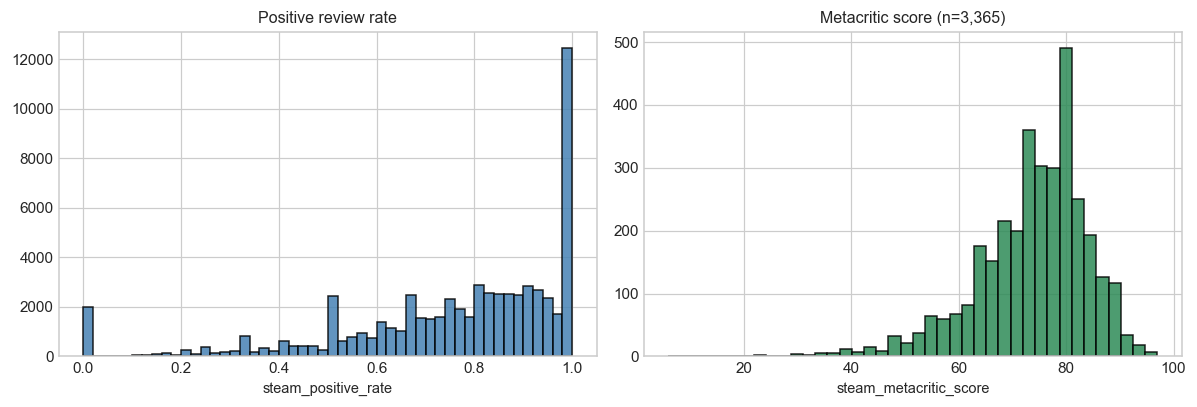

In [13]:
# Candidate targets that need no transformation
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["steam_positive_rate"].dropna(), bins=50, color="steelblue", edgecolor="black", alpha=0.85)
axes[0].set_title("Positive review rate")
axes[0].set_xlabel("steam_positive_rate")
mc = df.loc[df["steam_metacritic_score"] > 0, "steam_metacritic_score"]
axes[1].hist(mc, bins=40, color="seagreen", edgecolor="black", alpha=0.85)
axes[1].set_title(f"Metacritic score (n={len(mc):,})")
axes[1].set_xlabel("steam_metacritic_score")
plt.tight_layout()
save_fig(fig, "01_q3_targets_untransformed")
plt.show()

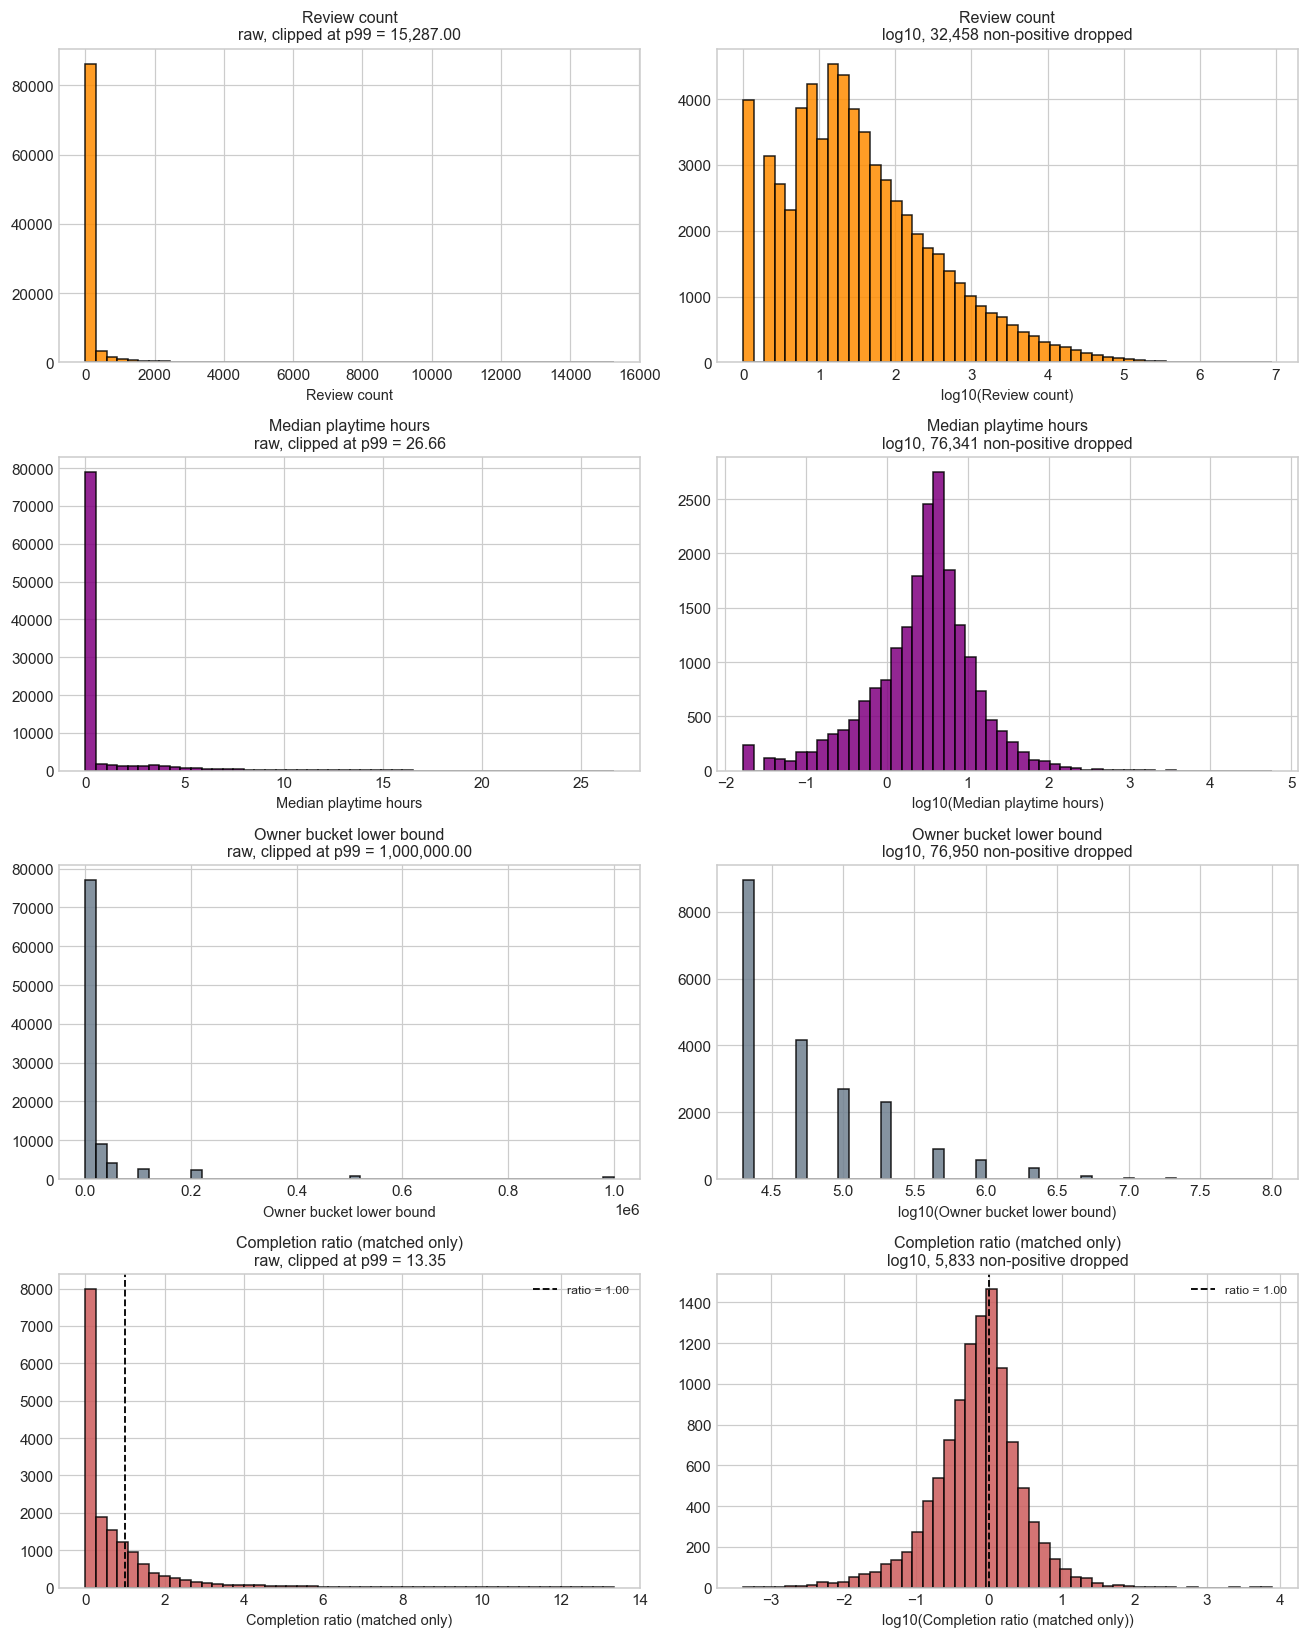

In [14]:
# Heavy-tailed candidate targets, raw on the left and log10 on the right
fig, axes = plt.subplots(4, 2, figsize=(12, 15))
raw_vs_log(axes[0], df["steam_review_count"].astype(float), "Review count", "darkorange")
raw_vs_log(axes[1], df["steam_playtime_hours"], "Median playtime hours", "purple")
raw_vs_log(axes[2], df["steam_owners_lower"], "Owner bucket lower bound", "slategray")
raw_vs_log(axes[3], matched["completion_ratio"], "Completion ratio (matched only)", "indianred")
axes[3][1].axvline(0, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[3][1].legend(fontsize=8)
axes[3][0].axvline(1, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[3][0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_q3_targets_raw_vs_log")
plt.show()

In [15]:
# The completion ratio in detail: zero inflation, tail, and its two components
cr_all = matched["completion_ratio"]
print(f"matched games               : {len(matched):,}")
print(f"  completion ratio is zero  : {(cr_all == 0).sum():,} ({(cr_all == 0).mean() * 100:.1f}%)  <- SteamSpy playtime of 0")
print(f"  ratio in (0, 1]           : {((cr_all > 0) & (cr_all <= 1)).sum():,}")
print(f"  ratio > 1                 : {(cr_all > 1).sum():,}")
print(f"  ratio > 5                 : {(cr_all > 5).sum():,}")
print("\nquantiles of the positive ratio:")
print(cr_all[cr_all > 0].quantile([0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3).to_string())

matched games               : 16,660
  completion ratio is zero  : 5,833 (35.0%)  <- SteamSpy playtime of 0
  ratio in (0, 1]           : 6,502
  ratio > 1                 : 4,325
  ratio > 5                 : 603

quantiles of the positive ratio:
0.01     0.012
0.25     0.339
0.50     0.769
0.75     1.479
0.95     5.408
0.99    19.045


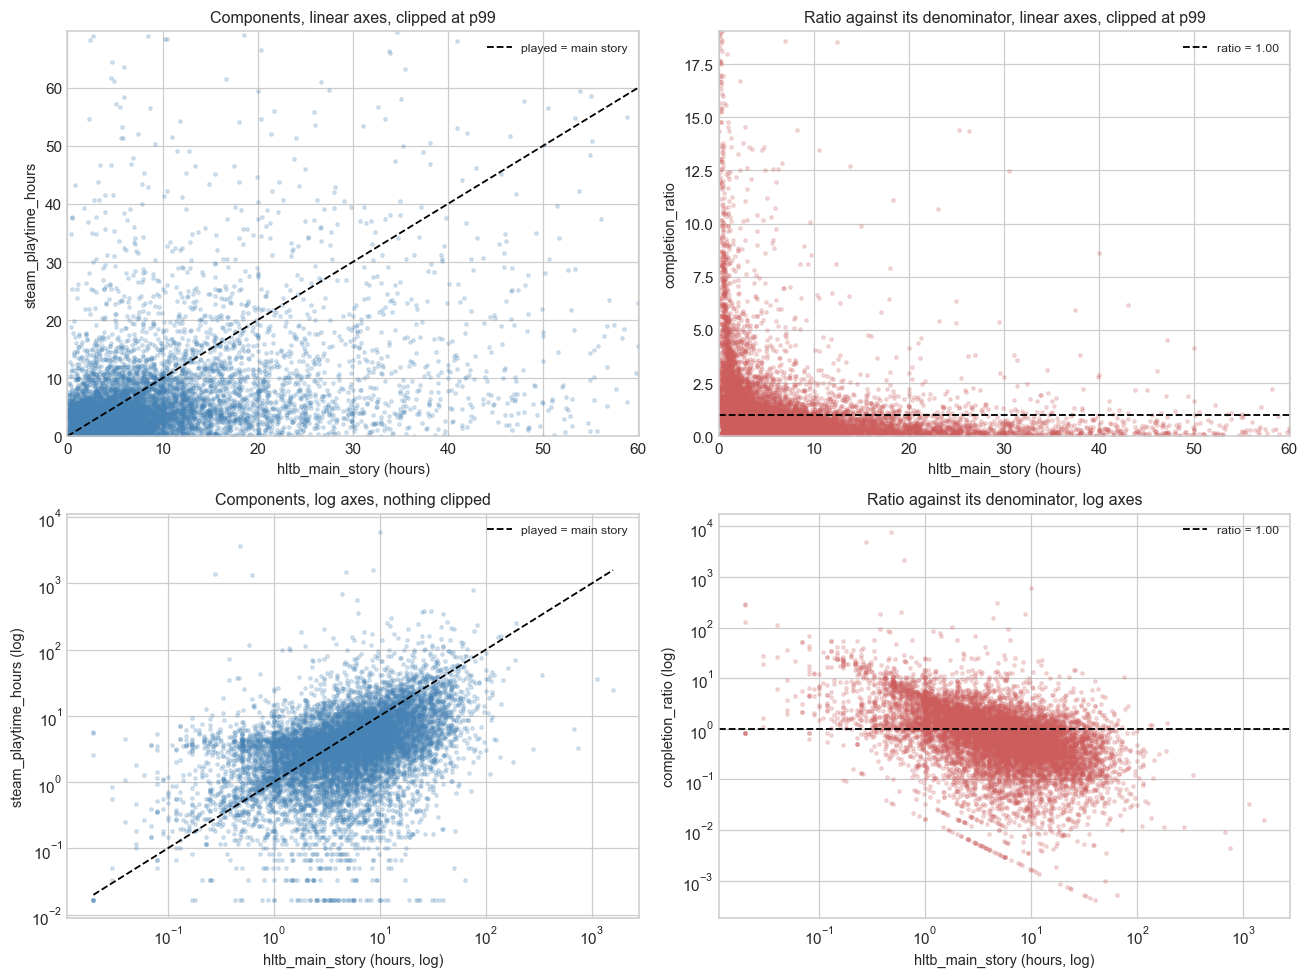

The right-hand panels divide by the quantity on their x axis, so a negative slope
appears from arithmetic alone. The left-hand panels show the same data without that.


In [16]:
# The two components, and the ratio, on linear axes and then on log axes
pos = matched[(matched["completion_ratio"] > 0) & (matched["hltb_main_story"] > 0)]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Row 0: linear axes, clipped so the bulk is visible
xc, yc = pos["hltb_main_story"].quantile(0.99), pos["steam_playtime_hours"].quantile(0.99)
axes[0, 0].scatter(pos["hltb_main_story"], pos["steam_playtime_hours"], s=5, alpha=0.2, color="steelblue")
axes[0, 0].plot([0, xc], [0, xc], color="black", linestyle="--", linewidth=1.2, label="played = main story")
axes[0, 0].set_xlim(0, xc); axes[0, 0].set_ylim(0, yc)
axes[0, 0].set_xlabel("hltb_main_story (hours)"); axes[0, 0].set_ylabel("steam_playtime_hours")
axes[0, 0].set_title("Components, linear axes, clipped at p99")
axes[0, 0].legend(fontsize=8)

axes[0, 1].scatter(pos["hltb_main_story"], pos["completion_ratio"], s=5, alpha=0.2, color="indianred")
axes[0, 1].axhline(1.0, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[0, 1].set_xlim(0, xc); axes[0, 1].set_ylim(0, pos["completion_ratio"].quantile(0.99))
axes[0, 1].set_xlabel("hltb_main_story (hours)"); axes[0, 1].set_ylabel("completion_ratio")
axes[0, 1].set_title("Ratio against its denominator, linear axes, clipped at p99")
axes[0, 1].legend(fontsize=8)

# Row 1: the same two plots on log axes
axes[1, 0].scatter(pos["hltb_main_story"], pos["steam_playtime_hours"], s=5, alpha=0.2, color="steelblue")
lims = [pos["hltb_main_story"].min(), pos["hltb_main_story"].max()]
axes[1, 0].plot(lims, lims, color="black", linestyle="--", linewidth=1.2, label="played = main story")
axes[1, 0].set_xscale("log"); axes[1, 0].set_yscale("log")
axes[1, 0].set_xlabel("hltb_main_story (hours, log)"); axes[1, 0].set_ylabel("steam_playtime_hours (log)")
axes[1, 0].set_title("Components, log axes, nothing clipped")
axes[1, 0].legend(fontsize=8)

axes[1, 1].scatter(pos["hltb_main_story"], pos["completion_ratio"], s=5, alpha=0.2, color="indianred")
axes[1, 1].axhline(1.0, color="black", linestyle="--", linewidth=1.2, label="ratio = 1.00")
axes[1, 1].set_xscale("log"); axes[1, 1].set_yscale("log")
axes[1, 1].set_xlabel("hltb_main_story (hours, log)"); axes[1, 1].set_ylabel("completion_ratio (log)")
axes[1, 1].set_title("Ratio against its denominator, log axes")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
save_fig(fig, "01_q3_completion_ratio_raw_vs_log")
plt.show()
print("The right-hand panels divide by the quantity on their x axis, so a negative slope")
print("appears from arithmetic alone. The left-hand panels show the same data without that.")

In [17]:
def extremes(frame, col, n=5):
    sub = frame[frame[col].notna()]
    out = pd.concat([sub.nlargest(n, col), sub.nsmallest(n, col)])[
        ["steam_name", col, "steam_review_count", "steam_playtime_hours", "hltb_main_story"]].copy()
    out["steam_name"] = ascii_names(out["steam_name"])
    return out.round(2)

print("--- Highest and lowest completion ratio (positive only) ---")
print(extremes(matched[matched["completion_ratio"] > 0], "completion_ratio").to_string(index=False))
print("\n--- Highest and lowest positive rate, among games with at least 500 reviews ---")
print(extremes(df[df["steam_review_count"] >= 500], "steam_positive_rate").to_string(index=False))

--- Highest and lowest completion ratio (positive only) ---
                                             steam_name  completion_ratio  steam_review_count  steam_playtime_hours  hltb_main_story
                                        Sisyphus Reborn           7722.47                1052               3706.78             0.48
                                            Rogue Agent           4897.20                 409               1371.22             0.28
                                 My Stepbro is a Femboy           2111.72                   0               1330.38             0.63
             Letters From a Rainy Day -Oceans and Lace-            592.93                 897               5994.57            10.11
Lay a Beauty to Rest: The Darkness Peach Blossom Spring            305.31                6464               1471.62             4.82
                                             7th Legion              0.00                  90                  0.02            40.00
         

### Interpretation: Choosing a target variable
**Author**: [Insert Name]  
<!-- This is the answer to AQ1. Evaluate each candidate target against what a studio needs to know and what the data can support: how many games it is defined for, how it is distributed on both the raw and log views, what its outliers are and whether they are real, and whether it measures success or merely exposure. Address the completion ratio directly, including its zero inflation and what the two components show when plotted separately. State which target or targets you carry into AQ2 and AQ3, and why you set the others aside. -->


## 4. What bias did the merge introduce?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the overall match rate is compared against the rate within audience-size buckets, then matched and unmatched games are compared directly. The standardised mean difference puts variables on a common scale, where an absolute value above 0.1 is the usual threshold for a meaningful imbalance.

In [18]:
steps = [
    ("Training rows", len(df)),
    ("Matched to HowLongToBeat", int(df["matched_hltb"].sum())),
    ("  and hltb_main_story > 0", int(((df["matched_hltb"]) & (df["hltb_main_story"] > 0)).sum())),
    ("  and playtime > 0 (ratio defined and non-zero)", int((df["completion_ratio"] > 0).sum())),
    ("  and at least 50 reviews", int(((df["completion_ratio"] > 0) & (df["steam_review_count"] >= 50)).sum())),
]
funnel = pd.DataFrame(steps, columns=["step", "games"])
funnel["pct_of_train"] = (funnel["games"] / len(df) * 100).round(1)
print(funnel.to_string(index=False))

                                           step  games  pct_of_train
                                  Training rows  97026         100.0
                       Matched to HowLongToBeat  16660          17.2
                        and hltb_main_story > 0  16660          17.2
  and playtime > 0 (ratio defined and non-zero)  10827          11.2
                        and at least 50 reviews   9857          10.2


                     games  matched  match_rate_pct
steam_review_bucket                                
0                    32458     2142             6.6
1-10                 21428      452             2.1
11-50                19316     2049            10.6
51-200               10740     3721            34.6
201-1k                7439     4255            57.2
1k-5k                 3521     2474            70.3
5k-20k                1346     1010            75.0
20k+                   778      557            71.6


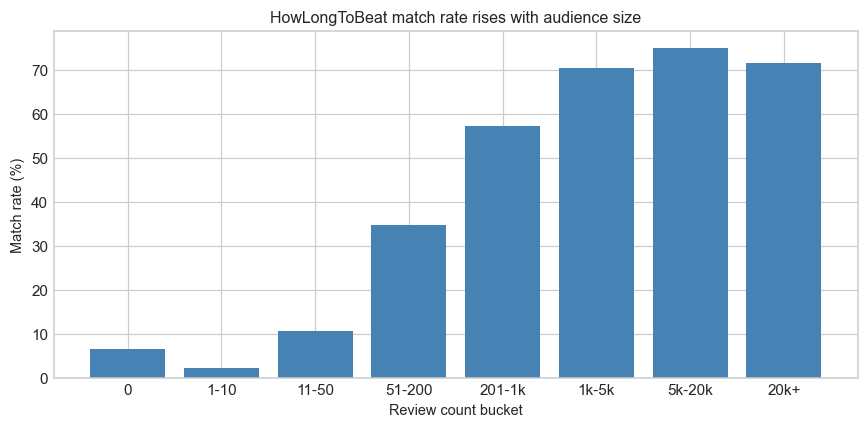

In [19]:
bins = [-1, 0, 10, 50, 200, 1000, 5000, 20000, np.inf]
labels = ["0", "1-10", "11-50", "51-200", "201-1k", "1k-5k", "5k-20k", "20k+"]
df["steam_review_bucket"] = pd.cut(df["steam_review_count"], bins=bins, labels=labels)

by_bucket = df.groupby("steam_review_bucket", observed=True).agg(
    games=("steam_appid", "size"), matched=("matched_hltb", "sum"))
by_bucket["match_rate_pct"] = (by_bucket["matched"] / by_bucket["games"] * 100).round(1)
print(by_bucket.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_bucket.index.astype(str), by_bucket["match_rate_pct"], color="steelblue")
ax.set_ylabel("Match rate (%)"); ax.set_xlabel("Review count bucket")
ax.set_title("HowLongToBeat match rate rises with audience size")
plt.tight_layout()
save_fig(fig, "01_q4_match_rate_by_reviews")
plt.show()

In [20]:
# Matched against unmatched, within single-player games that have some audience.
# Standardised mean difference puts every variable on a comparable scale:
# |SMD| above 0.1 is the usual threshold for a meaningful imbalance.
stratum = df[df["steam_categories"].fillna("").str.contains("Single-player") & (df["steam_review_count"] >= 50)]
a = stratum[stratum["matched_hltb"]]
b = stratum[~stratum["matched_hltb"]]

rows = []
for col in ["steam_review_count", "steam_positive_rate", "steam_price", "steam_achievements",
            "steam_language_count", "steam_years_since_release", "steam_playtime_hours", "steam_metacritic_score"]:
    m1, m2 = a[col].mean(), b[col].mean()
    s1, s2 = a[col].std(), b[col].std()
    pooled = np.sqrt((s1**2 + s2**2) / 2)
    rows.append({"variable": col, "matched_mean": m1, "unmatched_mean": m2,
                 "SMD": (m1 - m2) / pooled if pooled else np.nan})
smd = pd.DataFrame(rows).set_index("variable").round(3)
print(f"stratum: single-player with >= 50 reviews, n = {len(stratum):,}")
print(f"matched {len(a):,} ({len(a) / len(stratum) * 100:.1f}%), unmatched {len(b):,}\n")
print(smd.to_string())

stratum: single-player with >= 50 reviews, n = 22,701
matched 11,996 (52.8%), unmatched 10,705

                           matched_mean  unmatched_mean    SMD
variable                                                      
steam_review_count             5609.238        1946.595  0.112
steam_positive_rate               0.815           0.762  0.355
steam_price                       5.673           5.386  0.041
steam_achievements               37.377          51.775 -0.049
steam_language_count              6.410           5.292  0.126
steam_years_since_release         7.272           6.314  0.252
steam_playtime_hours              7.012           6.832  0.003
steam_metacritic_score           16.128           3.357  0.522


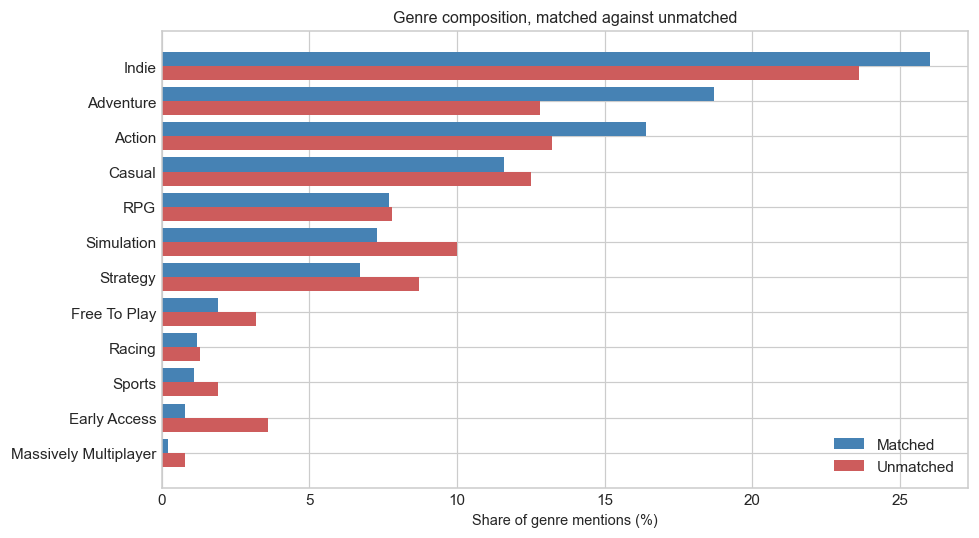

,matched_pct,unmatched_pct,difference
steam_genres,,,
Indie,26.0,23.6,2.4
Adventure,18.7,12.8,6.0
Action,16.4,13.2,3.2
Casual,11.6,12.5,-0.9
RPG,7.7,7.8,-0.1
Simulation,7.3,10.0,-2.7
Strategy,6.7,8.7,-2.0
Free To Play,1.9,3.2,-1.3
Racing,1.2,1.3,-0.1


In [21]:
def genre_share(frame):
    tok = frame["steam_genres"].fillna("").str.split(",").explode().str.strip()
    return tok[tok.ne("")].value_counts(normalize=True) * 100

shares = pd.DataFrame({"matched_pct": genre_share(a), "unmatched_pct": genre_share(b)}).fillna(0)
shares["difference"] = (shares["matched_pct"] - shares["unmatched_pct"]).round(1)
top = shares.nlargest(12, "matched_pct").round(1)

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top))
ax.barh(y - 0.2, top["matched_pct"], height=0.4, label="Matched", color="steelblue")
ax.barh(y + 0.2, top["unmatched_pct"], height=0.4, label="Unmatched", color="indianred")
ax.set_yticks(y); ax.set_yticklabels(top.index); ax.invert_yaxis()
ax.set_xlabel("Share of genre mentions (%)")
ax.set_title("Genre composition, matched against unmatched")
ax.legend()
plt.tight_layout()
save_fig(fig, "01_q4_genre_composition")
plt.show()
top

### Interpretation: Merge bias and representativeness
**Author**: [Insert Name]  
<!-- Judge whether the matched set is a representative sample of Steam games, and if not, in which direction it is skewed. Cover what the funnel costs at each step, what the match-rate gradient across review buckets implies, which variables show a meaningful standardised difference and what that does to any completion finding, and how you will state this limitation in the report. -->


## 5. What do the top games look like, against the rest?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: sorting a heavy-tailed variable puts anomalies at the top rather than well-known titles, so the playtime table excludes software and applies a review floor. The tables are followed by distribution comparisons, because a list of fifteen titles says nothing about whether those titles differ from everything else. Top is defined as the highest 1% on a measure, which is a cut-off rather than a judgement about quality.

In [22]:
cols = ["steam_name", "steam_year", "steam_price", "steam_review_count", "steam_positive_rate",
        "steam_playtime_hours", "hltb_main_story", "completion_ratio", "steam_metacritic_score"]

def top_table(frame, by, n=15, where=None):
    sub = frame if where is None else frame[where]
    out = sub.nlargest(n, by)[cols].copy()
    out["steam_name"] = ascii_names(out["steam_name"])
    return out.round(2)

print("=== Most reviewed games ===")
print(top_table(df, "steam_review_count").to_string(index=False))

=== Most reviewed games ===
                       steam_name  steam_year  steam_price  steam_review_count  steam_positive_rate  steam_playtime_hours  hltb_main_story  completion_ratio  steam_metacritic_score
                 Counter-Strike 2        2012         0.00             8815087                 0.87                103.95              NaN               NaN                       0
                           Dota 2        2013         0.00             2498969                 0.82                 19.25              NaN               NaN                      90
        Grand Theft Auto V Legacy        2015         0.00             1990556                 0.87                 97.43              NaN               NaN                      96
                         Terraria        2011         4.99             1409473                 0.97                 34.18            51.74              0.66                      83
Tom Clancy's Rainbow Six? Siege X        2015         0.00         

In [23]:
print("=== Highest median playtime, games only, at least 500 reviews ===")
mask = (~df["steam_is_software"]) & (df["steam_review_count"] >= 500)
print(top_table(df, "steam_playtime_hours", where=mask).to_string(index=False))

=== Highest median playtime, games only, at least 500 reviews ===
                                                    steam_name  steam_year  steam_price  steam_review_count  steam_positive_rate  steam_playtime_hours  hltb_main_story  completion_ratio  steam_metacritic_score
                    Letters From a Rainy Day -Oceans and Lace-        2021        11.89                 897                 0.98               5994.57            10.11            592.93                       0
                                               Sisyphus Reborn        2016         0.00                1052                 0.93               3706.78             0.48           7722.47                       0
                                                         GINKA        2023        13.79                2604                 0.91               1622.20             8.73            185.82                       0
       Lay a Beauty to Rest: The Darkness Peach Blossom Spring        2021         6.01       

In [24]:
mask_m = (matched["steam_review_count"] >= 500) & (matched["completion_ratio"] > 0)
print("=== Highest completion ratio, at least 500 reviews ===")
sub = matched[mask_m].nlargest(15, "completion_ratio")[cols].copy()
sub["steam_name"] = ascii_names(sub["steam_name"])
print(sub.round(2).to_string(index=False))

print("\n=== Lowest completion ratio, at least 500 reviews ===")
sub2 = matched[mask_m].nsmallest(15, "completion_ratio")[cols].copy()
sub2["steam_name"] = ascii_names(sub2["steam_name"])
print(sub2.round(2).to_string(index=False))

=== Highest completion ratio, at least 500 reviews ===
                                             steam_name  steam_year  steam_price  steam_review_count  steam_positive_rate  steam_playtime_hours  hltb_main_story  completion_ratio  steam_metacritic_score
                                        Sisyphus Reborn        2016         0.00                1052                 0.93               3706.78             0.48           7722.47                       0
             Letters From a Rainy Day -Oceans and Lace-        2021        11.89                 897                 0.98               5994.57            10.11            592.93                       0
Lay a Beauty to Rest: The Darkness Peach Blossom Spring        2021         6.01                6464                 0.97               1471.62             4.82            305.31                       0
                              BEAR, VODKA, STALINGRAD!?        2020         1.39                 973                 0.94            

In [25]:
# Label the top games so they can be compared against everything else.
# "Top" is the highest 1% on a measure, which is a cut-off rather than a judgement.
df["top_group"] = "Rest of population"
rev_cut = df["steam_review_count"].quantile(0.99)
play_cut = df.loc[~df["steam_is_software"], "steam_playtime_hours"].quantile(0.99)

df.loc[df["steam_playtime_hours"] >= play_cut, "top_group"] = "Top 1% playtime"
df.loc[df["steam_review_count"] >= rev_cut, "top_group"] = "Top 1% reviews"

order = ["Top 1% reviews", "Top 1% playtime", "Rest of population"]
print(f"review cut-off : {rev_cut:,.0f} reviews")
print(f"playtime cut-off: {play_cut:,.1f} hours\n")

profile = df.groupby("top_group").agg(
    games=("steam_appid", "size"),
    median_reviews=("steam_review_count", "median"),
    mean_positive_rate=("steam_positive_rate", "mean"),
    median_price=("steam_price", "median"),
    median_playtime_h=("steam_playtime_hours", "median"),
    median_achievements=("steam_achievements", "median"),
    median_languages=("steam_language_count", "median"),
    median_age_years=("steam_years_since_release", "median"),
    pct_matched=("matched_hltb", lambda s: s.mean() * 100),
).reindex(order)
profile.round(2)

review cut-off : 15,287 reviews
playtime cut-off: 25.7 hours



,games,median_reviews,mean_positive_rate,median_price,median_playtime_h,median_achievements,median_languages,median_age_years,pct_matched
top_group,,,,,,,,,
Top 1% reviews,971,35072.0,0.87,5.99,7.23,45.0,11.0,8.0,72.71
Top 1% playtime,930,360.5,0.80,7.99,45.83,24.0,3.0,5.0,40.00
Rest of population,95125,6.0,0.76,2.39,0.00,2.0,1.0,4.0,16.38


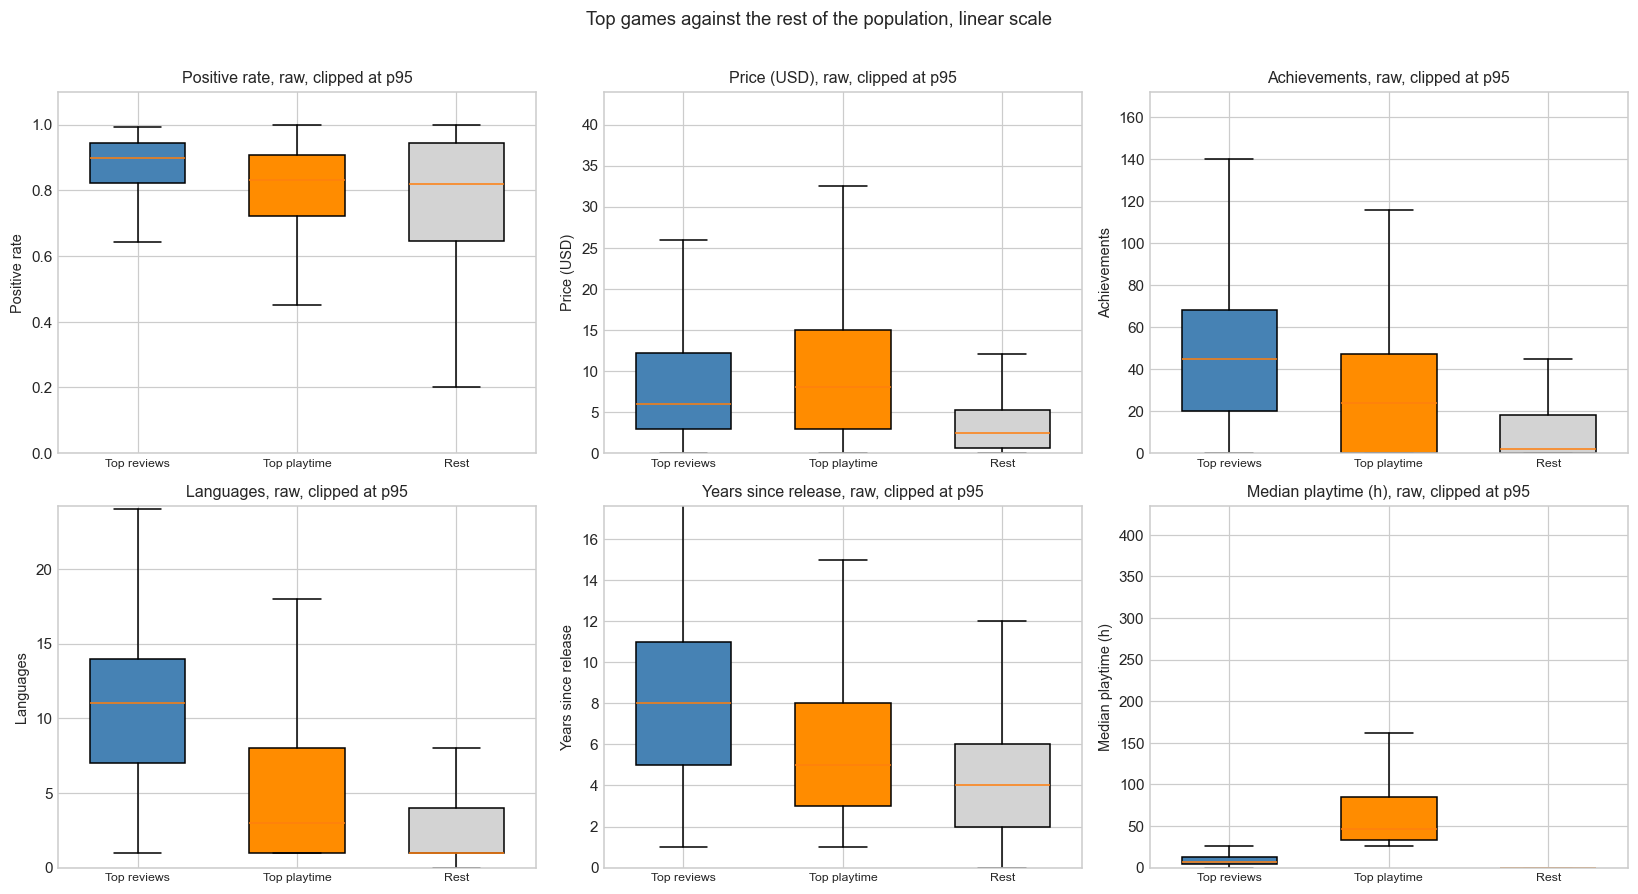

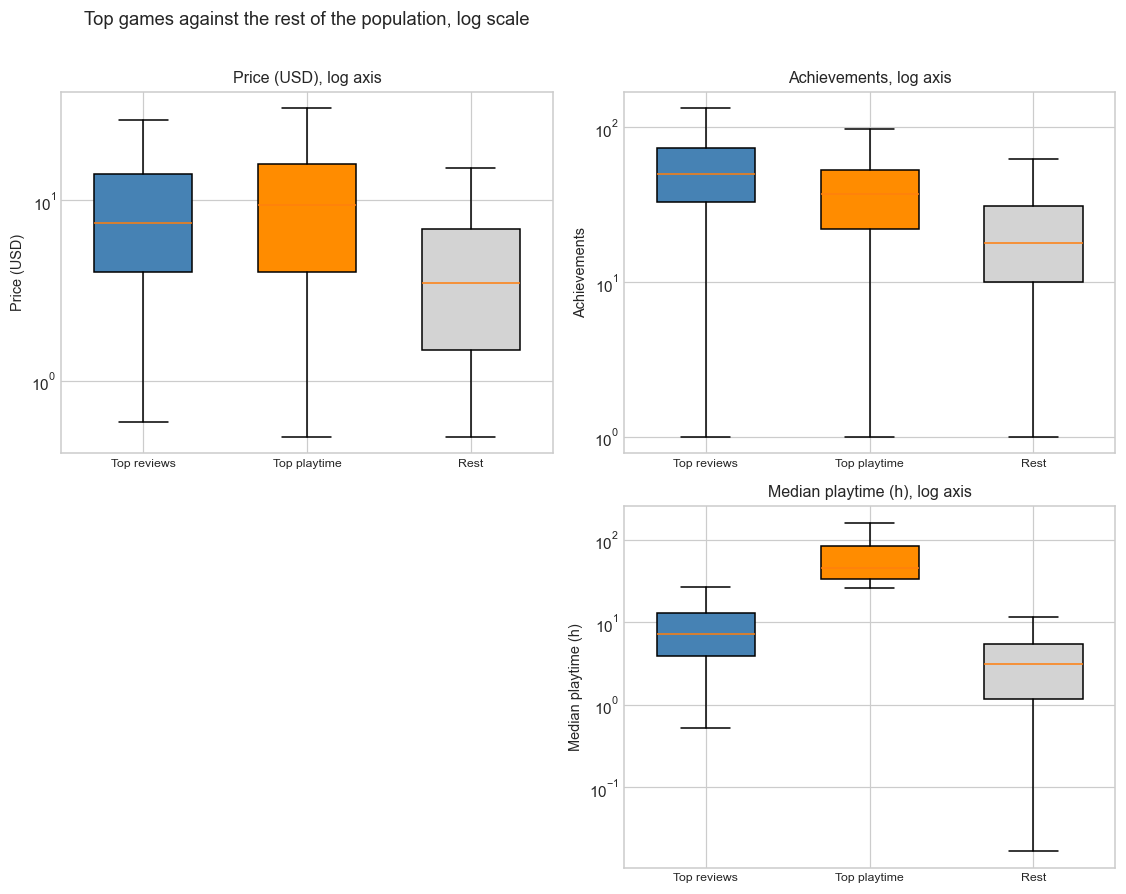

In [26]:
# Top games against the rest, on linear axes with the y range clipped so the
# boxes are readable, then on log axes so the tails are visible.
compare_cols = [
    ("steam_positive_rate", "Positive rate", False),
    ("steam_price", "Price (USD)", True),
    ("steam_achievements", "Achievements", True),
    ("steam_language_count", "Languages", False),
    ("steam_years_since_release", "Years since release", False),
    ("steam_playtime_hours", "Median playtime (h)", True),
]
palette = {"Top 1% reviews": "steelblue", "Top 1% playtime": "darkorange", "Rest of population": "lightgrey"}

for scale in ["linear", "log"]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, (col, label, loggable) in zip(axes.ravel(), compare_cols):
        data = [df.loc[df["top_group"].eq(g) & df[col].notna(), col] for g in order]
        if scale == "log":
            if not loggable:
                ax.set_visible(False)
                continue
            data = [d[d > 0] for d in data]
        bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
        for patch, g in zip(bp["boxes"], order):
            patch.set_facecolor(palette[g])
        ax.set_xticklabels(["Top reviews", "Top playtime", "Rest"], fontsize=8)
        ax.set_ylabel(label)
        if scale == "log":
            ax.set_yscale("log")
            ax.set_title(f"{label}, log axis")
        else:
            upper = max(d.quantile(0.95) for d in data if len(d))
            ax.set_ylim(bottom=0, top=upper * 1.1 if upper > 0 else None)
            ax.set_title(f"{label}, raw, clipped at p95")
    fig.suptitle(f"Top games against the rest of the population, {scale} scale", y=1.01)
    plt.tight_layout()
    save_fig(fig, f"01_q5_top_vs_rest_{scale}")
    plt.show()

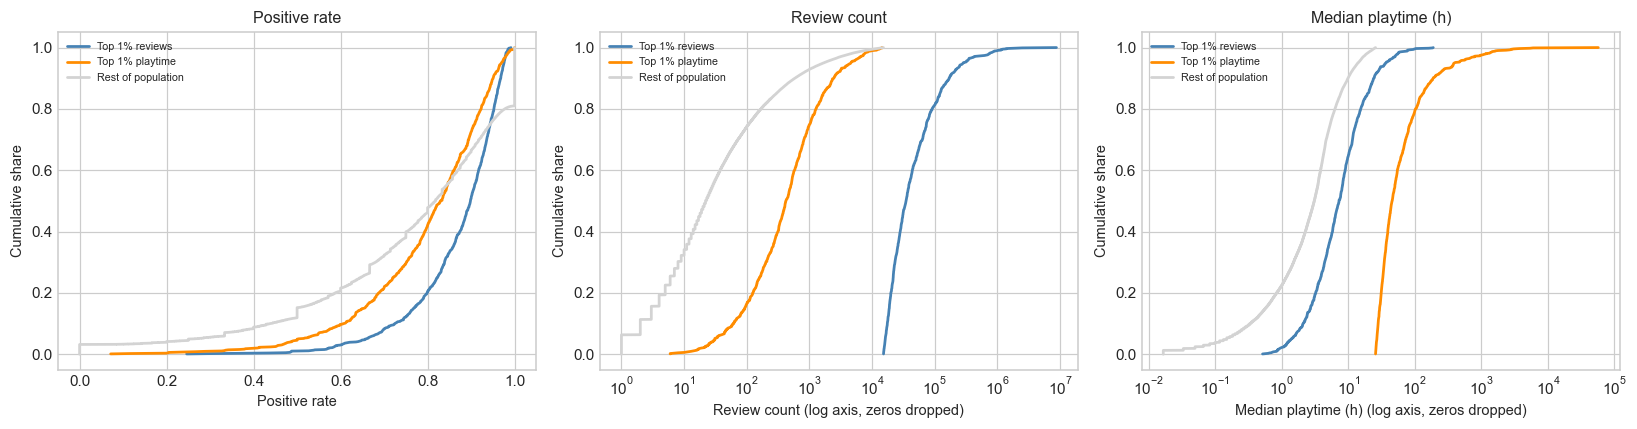

In [27]:
# Cumulative distributions make the whole population comparable at once
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (col, label, logx) in zip(axes, [
    ("steam_positive_rate", "Positive rate", False),
    ("steam_review_count", "Review count", True),
    ("steam_playtime_hours", "Median playtime (h)", True),
]):
    for g in order:
        s = df.loc[df["top_group"].eq(g) & df[col].notna(), col]
        if logx:
            s = s[s > 0]
        s = np.sort(s.values)
        if len(s) == 0:
            continue
        ax.plot(s, np.arange(1, len(s) + 1) / len(s), label=g, color=palette[g], linewidth=1.8)
    if logx:
        ax.set_xscale("log")
        ax.set_xlabel(f"{label} (log axis, zeros dropped)")
    else:
        ax.set_xlabel(label)
    ax.set_ylabel("Cumulative share")
    ax.set_title(label)
    ax.legend(fontsize=7)
plt.tight_layout()
save_fig(fig, "01_q5_top_vs_rest_ecdf")
plt.show()

### Interpretation: Top games against the rest of the population
**Author**: [Insert Name]  
<!-- Describe what the games at the top of each measure have in common and whether each list looks like a credible ranking of success. Cover how the most-reviewed list differs from the highest-playtime list, what kinds of games sit at the extremes of the completion ratio, and above all whether the top groups actually differ from the rest of the population on the controllable variables, or whether the box plots and cumulative curves overlap too much to separate them. Say what that implies about predicting success from these variables. -->


## 6. How does game age affect reception?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: two versions of the same curve. The unweighted mean treats every game equally, and the pooled rate is total positives over total reviews, which weights by how many reviews each game has. Both carry 95% error bars, and cohorts with fewer than 30 games are dropped. The review-count series is shown on a raw axis and then a log axis.

In [28]:
# Reception against game age, with standard errors.
# SE of a mean is sd / sqrt(n). The pooled rate is total positives over total
# reviews, which weights each game by how many reviews it has.
rated = df[df["steam_review_count"] > 0]
age = rated.groupby("steam_years_since_release").agg(
    games=("steam_appid", "size"),
    mean_rate=("steam_positive_rate", "mean"),
    sd_rate=("steam_positive_rate", "std"),
    total_pos=("steam_positive", "sum"),
    total_rev=("steam_review_count", "sum"),
    median_reviews=("steam_review_count", "median"),
)
age["se_rate"] = age["sd_rate"] / np.sqrt(age["games"])
age["pooled_rate"] = age["total_pos"] / age["total_rev"]
age["pooled_se"] = np.sqrt(age["pooled_rate"] * (1 - age["pooled_rate"]) / age["total_rev"])
age = age[age["games"] >= 30]
age[["games", "mean_rate", "se_rate", "pooled_rate", "pooled_se", "median_reviews"]].round(4)

,games,mean_rate,se_rate,pooled_rate,pooled_se,median_reviews
steam_years_since_release,,,,,,
1,4557,0.8401,0.0034,0.8499,0.0002,12.0
2,9602,0.8071,0.0026,0.8625,0.0001,13.0
3,7481,0.7812,0.0029,0.8418,0.0001,14.0
4,6657,0.7715,0.0029,0.8069,0.0002,17.0
5,6612,0.7570,0.0030,0.8535,0.0001,19.0
6,6258,0.7568,0.0029,0.8603,0.0001,22.0
7,5199,0.7345,0.0033,0.8736,0.0001,24.0
8,5648,0.7010,0.0031,0.8849,0.0001,29.0
9,4604,0.7038,0.0033,0.8593,0.0001,42.0


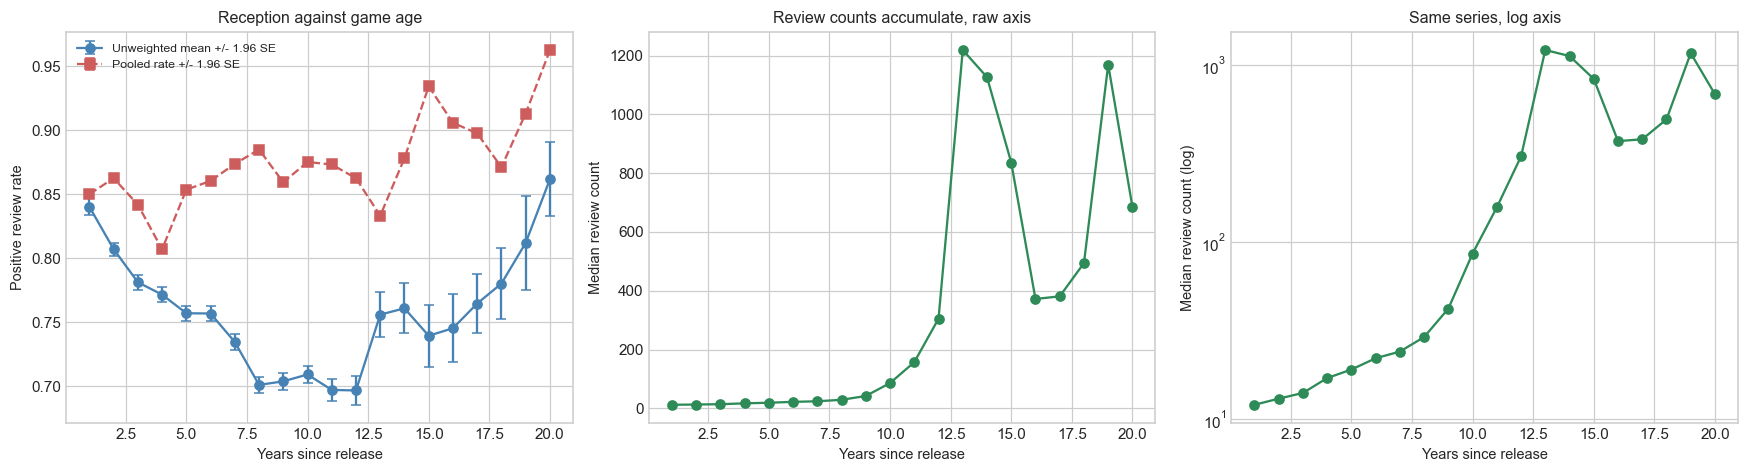

Error bars are narrow where a cohort has many games, so overlapping bars
matter more than the shape of the line.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

axes[0].errorbar(age.index, age["mean_rate"], yerr=1.96 * age["se_rate"], fmt="o-",
                 capsize=3, color="steelblue", label="Unweighted mean +/- 1.96 SE")
axes[0].errorbar(age.index, age["pooled_rate"], yerr=1.96 * age["pooled_se"], fmt="s--",
                 capsize=3, color="indianred", label="Pooled rate +/- 1.96 SE")
axes[0].set_xlabel("Years since release"); axes[0].set_ylabel("Positive review rate")
axes[0].set_title("Reception against game age")
axes[0].legend(fontsize=8)

axes[1].plot(age.index, age["median_reviews"], marker="o", color="seagreen")
axes[1].set_xlabel("Years since release"); axes[1].set_ylabel("Median review count")
axes[1].set_title("Review counts accumulate, raw axis")

axes[2].plot(age.index, age["median_reviews"], marker="o", color="seagreen")
axes[2].set_yscale("log")
axes[2].set_xlabel("Years since release"); axes[2].set_ylabel("Median review count (log)")
axes[2].set_title("Same series, log axis")

plt.tight_layout()
save_fig(fig, "01_q6_age_and_reception")
plt.show()
print("Error bars are narrow where a cohort has many games, so overlapping bars")
print("matter more than the shape of the line.")

### Interpretation: Game age and reception
**Author**: [Insert Name]  
<!-- Interpret the two curves and their error bars. Cover whether reception genuinely varies with age or whether the differences sit inside the error bars, why the unweighted and pooled curves may diverge, how much of any age pattern could be survivorship among older games rather than a real effect, and whether age needs to be controlled for in later models. -->


## 7. How do the variables correlate?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: Spearman rather than Pearson, since these variables are skewed and the relationships are not expected to be linear. Spearman works on ranks, so it is unaffected by whether a variable is logged. Shown on the full training set and on matched games only, since the completion ratio exists only in the latter.

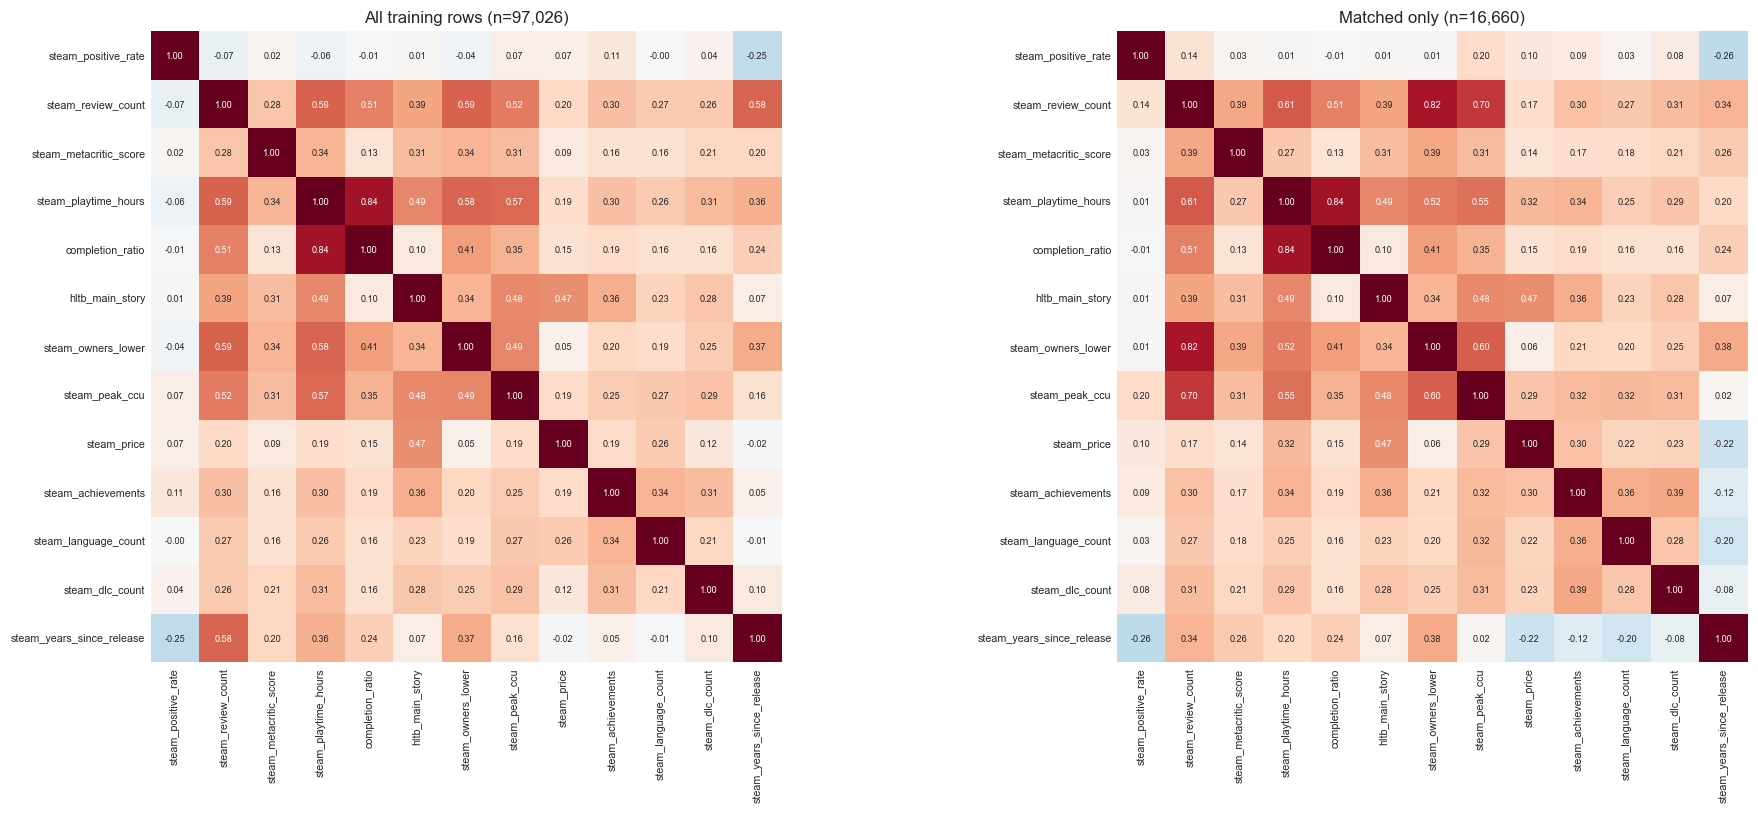

In [30]:
# Spearman rather than Pearson: these variables are skewed and the
# relationships are not expected to be linear.
num = ["steam_positive_rate", "steam_review_count", "steam_metacritic_score", "steam_playtime_hours",
       "completion_ratio", "hltb_main_story", "steam_owners_lower", "steam_peak_ccu", "steam_price",
       "steam_achievements", "steam_language_count", "steam_dlc_count", "steam_years_since_release"]

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (frame, label) in zip(axes, [(df, f"All training rows (n={len(df):,})"),
                                     (matched, f"Matched only (n={len(matched):,})")]):
    corr = frame[num].corr(method="spearman")
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                square=True, cbar=False, annot_kws={"size": 6}, ax=ax)
    ax.set_title(label, fontsize=11)
    ax.tick_params(labelsize=7)
plt.tight_layout()
save_fig(fig, "01_q7_spearman_correlation")
plt.show()

In [31]:
targets = ["steam_positive_rate", "steam_review_count", "steam_metacritic_score",
           "steam_playtime_hours", "completion_ratio", "steam_owners_lower"]
print("Spearman correlation among candidate targets, matched games only:")
print(matched[targets].corr(method="spearman").round(3).to_string())

Spearman correlation among candidate targets, matched games only:
                        steam_positive_rate  steam_review_count  steam_metacritic_score  steam_playtime_hours  completion_ratio  steam_owners_lower
steam_positive_rate                   1.000               0.143                   0.028                 0.010            -0.011               0.015
steam_review_count                    0.143               1.000                   0.390                 0.613             0.507               0.822
steam_metacritic_score                0.028               0.390                   1.000                 0.268             0.134               0.386
steam_playtime_hours                  0.010               0.613                   0.268                 1.000             0.842               0.519
completion_ratio                     -0.011               0.507                   0.134                 0.842             1.000               0.415
steam_owners_lower                    0.015   

### Interpretation: Correlation structure
**Author**: [Insert Name]  
<!-- Interpret the correlation structure. Cover which predictors move together closely enough to cause collinearity in a regression, how strongly the candidate targets agree with one another, whether the completion ratio carries information the review-based measures do not, and which relationships are strong enough to be worth modelling. -->


## 8. Suggested: how much evidence sits behind each estimate?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this section is not in the agreed list. It is included because the choice of target in AQ1 depends on how reliably each candidate is measured, not only on how it is distributed. Delete it if it is not wanted. The Wilson interval is used rather than the normal approximation, which misbehaves for proportions near 0 and 1 and at small sample sizes.

In [32]:
z = 1.96
rated = df[df["steam_review_count"] > 0].copy()
n, p = rated["steam_review_count"], rated["steam_positive_rate"]
half = (z / (1 + z**2 / n)) * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
rated["wilson_width"] = 2 * half

by_bucket = rated.groupby("steam_review_bucket", observed=True).agg(
    games=("steam_appid", "size"),
    median_reviews=("steam_review_count", "median"),
    mean_positive_rate=("steam_positive_rate", "mean"),
    median_ci_width=("wilson_width", "median"),
)
print("Precision of the positive rate by review count:")
print(by_bucket.round(3).to_string())

print("\nEvidence behind the HowLongToBeat main-story time:")
print(matched["hltb_main_story_polled"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_string())
print(f"matched games whose hltb_main_story rests on fewer than 5 reports: "
      f"{(matched['hltb_main_story_polled'] < 5).sum():,} "
      f"({(matched['hltb_main_story_polled'] < 5).mean() * 100:.1f}%)")

Precision of the positive rate by review count:
                     games  median_reviews  mean_positive_rate  median_ci_width
steam_review_bucket                                                            
1-10                 21428             4.0               0.730            0.603
11-50                19316            22.0               0.757            0.300
51-200               10740            94.0               0.760            0.152
201-1k                7439           396.0               0.786            0.071
1k-5k                 3521          1959.0               0.822            0.030
5k-20k                1346          8628.0               0.847            0.013
20k+                   778         44065.0               0.871            0.005

Evidence behind the HowLongToBeat main-story time:
count    16657.0
mean        37.1
std        188.2
min          1.0
10%          1.0
25%          1.0
50%          3.0
75%         11.0
90%         50.0
max       8013.0
matched ga

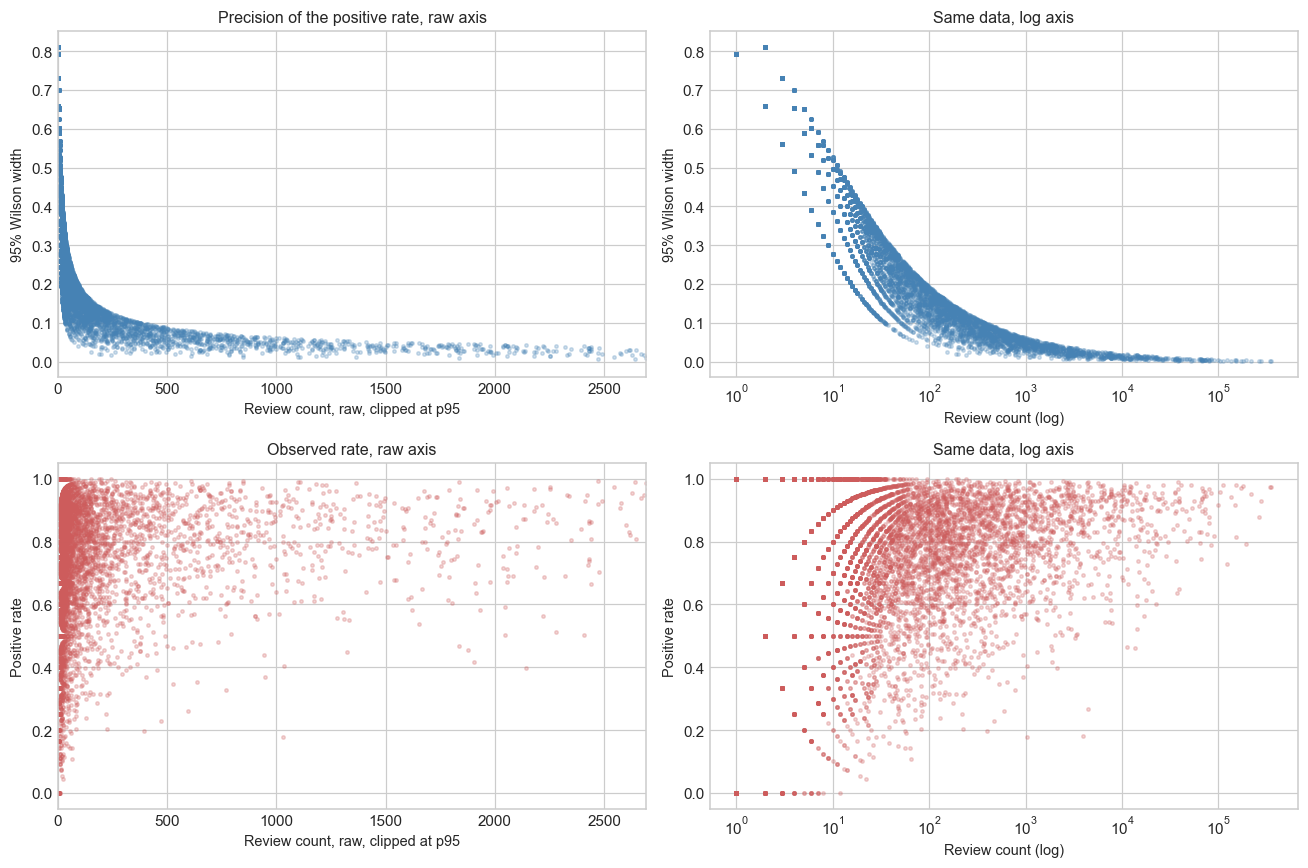

In [33]:
s = rated.sample(min(8000, len(rated)), random_state=config.SEED)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(s["steam_review_count"], s["wilson_width"], s=5, alpha=0.25, color="steelblue")
axes[0, 0].set_xlim(0, s["steam_review_count"].quantile(0.95))
axes[0, 0].set_xlabel("Review count, raw, clipped at p95"); axes[0, 0].set_ylabel("95% Wilson width")
axes[0, 0].set_title("Precision of the positive rate, raw axis")

axes[0, 1].scatter(s["steam_review_count"], s["wilson_width"], s=5, alpha=0.25, color="steelblue")
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlabel("Review count (log)"); axes[0, 1].set_ylabel("95% Wilson width")
axes[0, 1].set_title("Same data, log axis")

axes[1, 0].scatter(s["steam_review_count"], s["steam_positive_rate"], s=5, alpha=0.25, color="indianred")
axes[1, 0].set_xlim(0, s["steam_review_count"].quantile(0.95))
axes[1, 0].set_xlabel("Review count, raw, clipped at p95"); axes[1, 0].set_ylabel("Positive rate")
axes[1, 0].set_title("Observed rate, raw axis")

axes[1, 1].scatter(s["steam_review_count"], s["steam_positive_rate"], s=5, alpha=0.25, color="indianred")
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlabel("Review count (log)"); axes[1, 1].set_ylabel("Positive rate")
axes[1, 1].set_title("Same data, log axis")

plt.tight_layout()
save_fig(fig, "01_q8_evidence_raw_vs_log")
plt.show()

### Interpretation: Evidence behind the estimates
**Author**: [Insert Name]  
<!-- Interpret how much the precision of each measure varies across games. Cover how wide the interval on the positive rate is for a game at the low end against the high end, how many games rest on very few HowLongToBeat reports, and whether the right response is a minimum-evidence threshold, partial pooling, or carrying the uncertainty through the model. -->


## Save for stage 02
*Code: Generated by AI Assistant*

*Written by AI Assistant*: this stage adds derived columns and filters no rows, so the count out matches the count in. The cleaning decisions raised above belong to stage 02.

In [34]:
df.to_parquet(config.INTERIM / "01_eda.parquet", index=False)
print(f"rows in : {len(train):,}")
print(f"rows out: {len(df):,}  (no rows filtered in this stage)")
print(f"columns : {train.shape[1]} in, {df.shape[1]} out")
print(f"figures : {len(list(config.FIGURES.glob('01_*.png')))} written to outputs/figures")

rows in : 97,026
rows out: 97,026  (no rows filtered in this stage)
columns : 72 in, 84 out
figures : 13 written to outputs/figures
